In [1]:
import pandas as pd
import numpy as np

In [2]:
phishing = pd.read_csv("phishing_email.csv")
ceas = pd.read_csv("CEAS_08.csv")
enron = pd.read_csv("Enron.csv")
ling = pd.read_csv("Ling.csv")
nazario = pd.read_csv("Nazario.csv")
fraud = pd.read_csv("Nigerian_Fraud.csv")
spam = pd.read_csv("SpamAssasin.csv")   #data loaded

In [3]:
datasets={
    "phishing": phishing,
    "ceas": ceas,
    "enron": enron,
    "ling": ling,
    "nazario": nazario,
    "fraud": fraud,
    "spam": spam
}                        #dataset are saved under a single dataset dictionary

for name, df in datasets.items():  #iterates each item(dataset)
    print(f"\n{name}")
    print(df.columns)


phishing
Index(['text_combined', 'label'], dtype='object')

ceas
Index(['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls'], dtype='object')

enron
Index(['subject', 'body', 'label'], dtype='object')

ling
Index(['subject', 'body', 'label'], dtype='object')

nazario
Index(['sender', 'receiver', 'date', 'subject', 'body', 'urls', 'label'], dtype='object')

fraud
Index(['sender', 'receiver', 'date', 'subject', 'body', 'urls', 'label'], dtype='object')

spam
Index(['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls'], dtype='object')


In [4]:
STANDARD_COLUMNS = [ 
    "sender",
    "receiver",
    "date",
    "subject",
    "body",
    "urls",
    "label"
]                      #creating unified sturcture

In [5]:
#enron lacks sender receiver date and urls
for col in ["sender","receiver","date","urls"]:
    enron[col] = ""                 #seting empty value for these columns      
enron = enron[STANDARD_COLUMNS]     #aranging them in standard order

In [6]:
#ling lacks sender receiver date and urls
for col in ["sender","receiver","date","urls"]:
    ling[col] = ""                  #seting empty value for these columns
ling = ling[STANDARD_COLUMNS]       #aranging them in standard order

In [7]:
phishing["subject"] = ""
phishing["body"] = phishing["text_combined"]  #changing column name

for col in ["sender","receiver","date","urls"]:
    phishing[col] = ""

phishing = phishing[STANDARD_COLUMNS]

In [8]:
#the following datasets have all the standard columns so just aranging
ceas = ceas[STANDARD_COLUMNS]
nazario = nazario[STANDARD_COLUMNS]
fraud = fraud[STANDARD_COLUMNS]
spam = spam[STANDARD_COLUMNS]

In [9]:
combined_df = pd.concat([
    phishing,
    ceas,
    enron,
    ling,
    nazario,
    fraud,
    spam
], ignore_index= True) #combining the datasets
    

In [10]:
combined_df.shape

(164972, 7)

In [11]:
combined_df.head()

,sender,receiver,date,subject,body,urls,label
0,,,,,hpl nom may 25 2001 see attached file hplno 52...,,0
1,,,,,nom actual vols 24 th forwarded sabrae zajac h...,,0
2,,,,,enron actuals march 30 april 1 201 estimated a...,,0
3,,,,,hpl nom may 30 2001 see attached file hplno 53...,,0
4,,,,,hpl nom june 1 2001 see attached file hplno 60...,,0


In [12]:
combined_df["label"].value_counts()

label
1    85782
0    79190
Name: count, dtype: int64

In [13]:
combined_df["label"] = combined_df["label"].replace({
    "ham":0,                #replacing every lable with 0s and 1s 
    "legitimate":0,
    "safe":0,

    "spam":1,
    "phishing":1,
    "fraud": 1
})                          #0-> legitimate 1->phishing

In [14]:
combined_df["label"].value_counts()

label
1    85782
0    79190
Name: count, dtype: int64

In [15]:
combined_df.to_csv(
    "master_phishing_dataset.csv",
    index = False
)

In [16]:
combined_df.info()
combined_df.head()
combined_df["label"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164972 entries, 0 to 164971
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   sender    164641 non-null  object
 1   receiver  162880 non-null  object
 2   date      164489 non-null  object
 3   subject   164625 non-null  object
 4   body      164971 non-null  object
 5   urls      164972 non-null  object
 6   label     164972 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 8.8+ MB


label
1    85782
0    79190
Name: count, dtype: int64

In [17]:
combined_df.isnull().sum()

sender       331
receiver    2092
date         483
subject      347
body           1
urls           0
label          0
dtype: int64

In [18]:
import pandas as pd

df = pd.read_csv("master_phishing_dataset.csv")

In [19]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164972 entries, 0 to 164971
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   sender    49529 non-null   object 
 1   receiver  47768 non-null   object 
 2   date      49377 non-null   object 
 3   subject   82139 non-null   object 
 4   body      164971 non-null  object 
 5   urls      49860 non-null   float64
 6   label     164972 non-null  int64  
dtypes: float64(1), int64(1), object(5)
memory usage: 8.8+ MB


,sender,receiver,date,subject,body,urls,label
0,NaN,NaN,NaN,NaN,hpl nom may 25 2001 see attached file hplno 52...,NaN,0
1,NaN,NaN,NaN,NaN,nom actual vols 24 th forwarded sabrae zajac h...,NaN,0
2,NaN,NaN,NaN,NaN,enron actuals march 30 april 1 201 estimated a...,NaN,0
3,NaN,NaN,NaN,NaN,hpl nom may 30 2001 see attached file hplno 53...,NaN,0
4,NaN,NaN,NaN,NaN,hpl nom june 1 2001 see attached file hplno 60...,NaN,0


In [20]:
df.fillna("", inplace=True)

C:\Users\Aravindon_Annadurai\AppData\Local\Temp\ipykernel_25916\2065217620.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.fillna("", inplace=True)


In [21]:
df.isnull().sum()

sender      0
receiver    0
date        0
subject     0
body        0
urls        0
label       0
dtype: int64

In [22]:
duplicates = df.duplicated().sum()
print(duplicates)

408


In [23]:
df.drop_duplicates(inplace=True)

In [24]:
duplicates = df.duplicated().sum()
print(duplicates)

0


In [25]:
df.shape

(164564, 7)

In [26]:
df["email_text"] = (
    df["subject"].astype(str)
    + " "
    + df["body"].astype(str)
)

In [27]:
df["email_text"] = (
    df["email_text"]
    .str.lower()
)

In [28]:
import re

def remove_html(text):
    return re.sub(r'<.*?>', ' ', str(text))

In [29]:
df["email_text"] = (
    df["email_text"]
    .apply(remove_html)
)

In [30]:
def replace_urls(text):
    return re.sub(
        r'http[s]?://\S+',
        ' URL ',
        text
    )

In [31]:
df["email_text"] = (
    df["email_text"]
    .apply(replace_urls)
)

In [32]:
def remove_emails(text):
    return re.sub(
        r'\S+@\S+',
        ' EMAIL ',
        text
    )

In [33]:
df["email_text"] = (
    df["email_text"]
    .apply(remove_emails)
)

In [34]:
def clean_symbols(text):
    return re.sub(
        r'[^a-zA-Z ]',
        ' ',
        text
    )

In [35]:
df["email_text"] = (
    df["email_text"]
    .apply(clean_symbols)
)

In [36]:
def remove_spaces(text):
    return " ".join(text.split())

In [37]:
df["email_text"] = (
    df["email_text"]
    .apply(remove_spaces)
)

In [38]:
df.to_csv(
    "clean_phishing_dataset.csv",
    index=False
)

In [39]:
for i in range(5):
    print(df["email_text"].iloc[i])
    print("="*80)

hpl nom may see attached file hplno xls hplno xls
nom actual vols th forwarded sabrae zajac hou ect pm enron capital trade resources corp eileen ponton davilal txu com cstonel txu com mjones txu com hpl scheduling enron com liz bellamy enron com szajac enron com cc subject nom actual vols th agree nomination forwarded eileen ponton houston pefs pec charlie stone eileen ponton melissa jones com hpl scheduling enron com liz bellamy enron com szajac enron com subject nom actual vols th pm agree nominated volume records reflect following nom schedule rate eff hrs hour beginning hrs rate eff hrs hour beginning hrs rate eff hrs hour beginning hrs total nominated please review source data let us know agree thanks ccs eileen ponton pm david avila lsp enserch us tu charlie stone energy txu tu melissa jones energy txu tu hpl scheduling enron com liz bellamy enron com szajac enron com cc subject nom actual vols th nom mcf mmbtu
enron actuals march april estimated actuals march flow march flow apr

In [40]:
print(df.shape)

print(df["label"].value_counts())

df["email_text"].head()

(164564, 8)
label
1    85736
0    78828
Name: count, dtype: int64


0    hpl nom may see attached file hplno xls hplno xls
1    nom actual vols th forwarded sabrae zajac hou ...
2    enron actuals march april estimated actuals ma...
3    hpl nom may see attached file hplno xls hplno xls
4    hpl nom june see attached file hplno xls hplno...
Name: email_text, dtype: object

In [41]:
df["email_text"].str.contains("EMAIL").sum()

np.int64(15821)

In [42]:
df.shape
df["label"].value_counts()


label
1    85736
0    78828
Name: count, dtype: int64

In [43]:
df["email_length"] = df["email_text"].apply(len)

In [44]:
df[["email_text","email_length"]].head()

,email_text,email_length
0,hpl nom may see attached file hplno xls hplno xls,49
1,nom actual vols th forwarded sabrae zajac hou ...,880
2,enron actuals march april estimated actuals ma...,109
3,hpl nom may see attached file hplno xls hplno xls,49
4,hpl nom june see attached file hplno xls hplno...,50


In [45]:
df["word_count"] = df["email_text"].apply(
    lambda x: len(str(x).split())
)

In [46]:
df["exclamation_count"] = (
    df["body"]
    .astype(str)
    .str.count("!")
)

In [47]:
urgency_words = [
    "urgent",
    "immediately",
    "verify",
    "suspended",
    "expire",
    "action required"
]

credential_words = [
    "password",
    "login",
    "account",
    "bank",
    "credit card"
]

threat_words = [
    "blocked",
    "disabled",
    "terminated",
    "warning",
    "security alert"
]                         #creating keywords

In [48]:
def count_keywords(text, keywords):
    return sum(
        word in text
        for word in keywords
    )

In [49]:
df["urgency_score"] = (
    df["email_text"]
    .apply(
        count_keywords, args=(urgency_words,)
    )
)

In [50]:
df["credential_score"] = (
    df["email_text"]
    .apply(
        count_keywords, args=(credential_words,)
    )
)

In [51]:
df["threat_score"] = (
    df["email_text"]
    .apply(
        count_keywords, args=(threat_words,)
    )
)

In [52]:
df['url_count'] = (
    df['urls']
        .astype(str)
        .apply(lambda x: len(x.split())
              )
)

In [53]:
df["has_url"] = (
    df["url_count"]>0
).astype(int)

In [54]:
df["has_url"].unique()

array([0, 1])

In [55]:
def get_domain(email):
    email = str(email).strip()
    if "@" in str(email):
        return email.split("@")[-1].strip(" >").lower()
    else:
        return ""

In [56]:
df["sender_domain"] = (
    df["sender"]
    .apply(get_domain)
)

In [57]:
df["sender_domain"].unique()

array(['', 'iworld.de', 'icable.ph', ..., 'aa64.toplinequotes.com',
       'yahoo.lv', 'dialix.oz.au'], shape=(19397,), dtype=object)

In [58]:
df['sender'].unique()

array(['', 'Young Esposito <Young@iworld.de>',
       "Mok <ipline's1983@icable.ph>", ..., 'Mike <raye@yahoo.lv>',
       '"Mr. Clean" <cweqx@dialix.oz.au>',
       '"wilsonkamela400@netscape.net" <wilsonkamela500@netscape.net>'],
      shape=(31416,), dtype=object)

In [59]:
!pip install scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [60]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(          #inbuilt vectorizer function
    max_features=5000,            #limit the wors to 5000
    stop_words="english"          # removes words like is, was, thw in eng lang
)

In [61]:
x_tfidf = tfidf.fit_transform(   #scans the emails and learns vocabulary and transforms it tonumerical feature
    df["email_text"]
)

In [62]:
print(x_tfidf.shape)

(164564, 5000)


In [63]:
manual_features = [
    "email_length",
    "word_count",
    "urgency_score",
    "credential_score",
    "threat_score",
    "url_count",
    "has_url"
]

In [64]:
x_manual = df[manual_features]  #all calcuated numerical features in a single variable
y = df["label"]    

In [65]:
x_manual

,email_length,word_count,urgency_score,credential_score,threat_score,url_count,has_url
0,49,10,0,0,0,0,0
1,880,152,0,0,0,0,0
2,109,17,0,0,0,0,0
3,49,10,0,0,0,0,0
4,50,10,0,0,0,0,0
...,...,...,...,...,...,...,...
164967,1926,314,0,1,0,1,1
164968,2002,348,0,0,0,1,1
164969,1837,340,0,0,0,1,1
164970,20317,3245,0,0,0,1,1


In [66]:
###save processed dataset
df.to_csv(
    "feature_engineered_dataset.csv",
    index = False
)

In [67]:
###save tf-idf vocabulary
import pickle            #used to save the derived file in project folder directly
f = open("tfidf_vectorizer.pkl", "wb")
pickle.dump(tfidf, f)

In [68]:
print(df[[
    "email_length",
    "word_count",
    "urgency_score",
    "credential_score",
    "threat_score",
    "url_count"
]].head())

   email_length  word_count  urgency_score  credential_score  threat_score  \
0            49          10              0                 0             0   
1           880         152              0                 0             0   
2           109          17              0                 0             0   
3            49          10              0                 0             0   
4            50          10              0                 0             0   

   url_count  
0          0  
1          0  
2          0  
3          0  
4          0  


In [69]:
print(x_tfidf.shape)

(164564, 5000)


In [70]:
#import librariees
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix,
classification_report
)

In [71]:
#first model useing tfidf
x = x_tfidf
y = df["label"]

In [72]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,   #20% testing size
    random_state=42, #to select same tsting samples in every run
    stratify=y       #to maintain legitimate and pishing ratio
)

In [73]:
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(x_train, y_train)  #training model

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [74]:
y_pred = lr.predict(x_test) #testing model/ making predictions

In [75]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.9831373621365418


In [76]:
precision = precision_score(
    y_test,
    y_pred
)

print("Precision:", precision)

Precision: 0.9817094414121472


In [77]:
recall = recall_score(
    y_test,
    y_pred
)

print("Recall:", recall)

Recall: 0.986003382515892


In [78]:
f1 = f1_score(
    y_test,
    y_pred
)

print("F1:", f1)  

F1: 0.9838517268468678


In [79]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[15451   315]
 [  240 16907]]


In [80]:
class_report_lr=   classification_report(
        y_test,
        y_pred
    )
print(class_report_lr)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     15766
           1       0.98      0.99      0.98     17147

    accuracy                           0.98     32913
   macro avg       0.98      0.98      0.98     32913
weighted avg       0.98      0.98      0.98     32913



In [81]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,        #setting number of random trees 
    random_state=42,
    n_jobs=-1                #uses maximum cpu cores to faster proccess
)

rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [82]:
rf_pred = rf.predict(x_test)  #testing data

In [83]:
class_report_rf = classification_report(
        y_test,
        rf_pred
    )
print(class_report_rf)

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     15766
           1       0.99      0.99      0.99     17147

    accuracy                           0.99     32913
   macro avg       0.99      0.99      0.99     32913
weighted avg       0.99      0.99      0.99     32913



In [84]:
#as rf performs better 

f = open("phishing_model.pkl", "wb")
pickle.dump(rf, f)

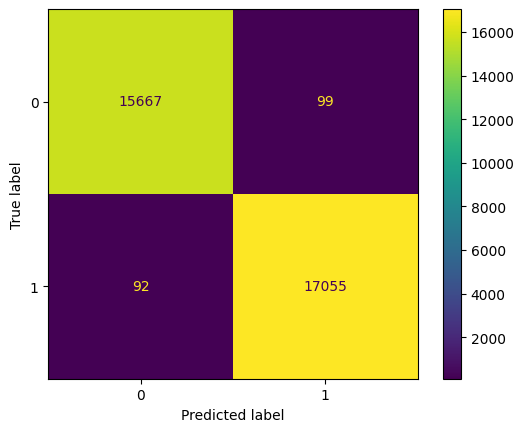

In [85]:
from sklearn.metrics import ConfusionMatrixDisplay  #confusion matrix of rf

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred
)


In [86]:
!pip install xgboost


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
from xgboost import XGBClassifier

In [88]:
xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)                                  #creating model

In [89]:
#train XG model
xgb.fit(x_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [90]:
#test XG model
xgb_pred = xgb.predict(x_test)

In [91]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.99      0.95      0.97     15766
           1       0.96      0.99      0.97     17147

    accuracy                           0.97     32913
   macro avg       0.97      0.97      0.97     32913
weighted avg       0.97      0.97      0.97     32913



In [92]:
### hyperparameter tuning

In [93]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier           

In [94]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)                                 #baseline xgboost model

In [95]:
param_dist = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5,],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}                                #defineing parameters

In [96]:
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=10,
    scoring="f1",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=1
)                             #creating randamized search

In [97]:
random_search.fit(x_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=1.0; total time=  55.4s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=1.0; total time=  56.5s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=1.0; total time=  58.7s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=1.0; total time=  47.5s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=1.0; total time=  43.5s
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=5, n_estimators=200, subsample=1.0; total time= 1.5min
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=5, n_estimators=200, subsample=1.0; total time= 1.6min
[CV] END colsample_bytree=0.8, learning_rate=0.1, max_depth=5, n_estimators=200, subsample=1.0; total time= 1.8min
[CV] END colsample_

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'n_estimators': [100, 200], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected `

In [98]:
print("Best Parameters:")
print(random_search.best_params_)   #view best parameters

Best Parameters:
{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


In [99]:
print("Best F1 Score:")
print(random_search.best_score_)  #best cross - validation score

Best F1 Score:
0.9673991029812277


In [100]:
best_xgb = random_search.best_estimator_ #get best model

In [101]:
best_pred = best_xgb.predict(x_test)    #predict on the test set

In [102]:
from sklearn.metrics import classification_report

print(classification_report(y_test, best_pred))    #evaluate

              precision    recall  f1-score   support

           0       0.98      0.95      0.97     15766
           1       0.95      0.99      0.97     17147

    accuracy                           0.97     32913
   macro avg       0.97      0.97      0.97     32913
weighted avg       0.97      0.97      0.97     32913



In [103]:
#computing matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

xgb_accuracy = accuracy_score(y_test, best_pred)
xgb_precision = precision_score(y_test, best_pred)
xgb_recall = recall_score(y_test, best_pred)
xgb_f1 = f1_score(y_test, best_pred)

print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)                 

Accuracy : 0.967611582049646
Precision: 0.9532668132363719
Recall   : 0.9861783402344434
F1 Score : 0.9694433297024594


In [104]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr_accuracy = accuracy_score(y_test, y_pred)
lr_precision = precision_score(y_test, y_pred)
lr_recall = recall_score(y_test, y_pred)
lr_f1 = f1_score(y_test, y_pred)            #to compare


In [105]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)          #to compare

In [106]:
xgb_accuracy = accuracy_score(y_test, best_pred)
xgb_precision = precision_score(y_test, best_pred)
xgb_recall = recall_score(y_test, best_pred)
xgb_f1 = f1_score(y_test, best_pred)       #to compare

In [107]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        lr_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        lr_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        lr_f1,
        rf_f1,
        xgb_f1
    ]
})

print(comparison)               #printing comparison

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.983137   0.981709  0.986003  0.983852
1        Random Forest  0.994197   0.994229  0.994635  0.994432
2              XGBoost  0.967612   0.953267  0.986178  0.969443


In [108]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_xgb,
    x_tfidf,
    y,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

print("Cross Validation Scores:")
print(cv_scores)

print("Average F1 Score:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())
#to demonstrate the consistency of the model

Cross Validation Scores:
[0.95452095 0.9736827  0.96065113 0.96629341 0.944183  ]
Average F1 Score: 0.9598662396133388
Standard Deviation: 0.010073287136576046


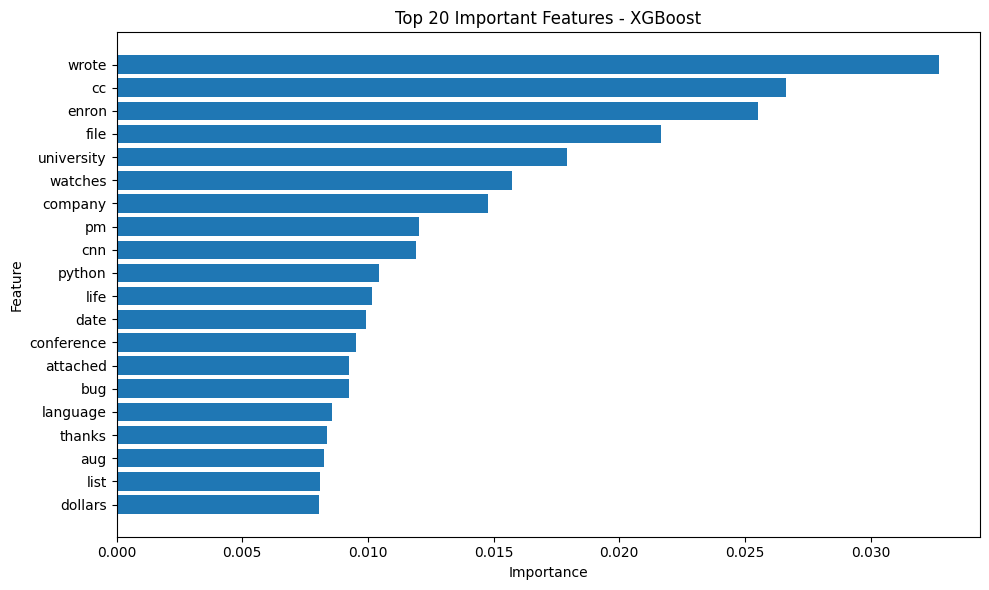

In [109]:
import matplotlib.pyplot as plt
feature_names = tfidf.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_xgb.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

top20 = importance.head(20)

plt.figure(figsize=(10,6))
plt.barh(top20["Feature"], top20["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Important Features - XGBoost")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()                       #visualization

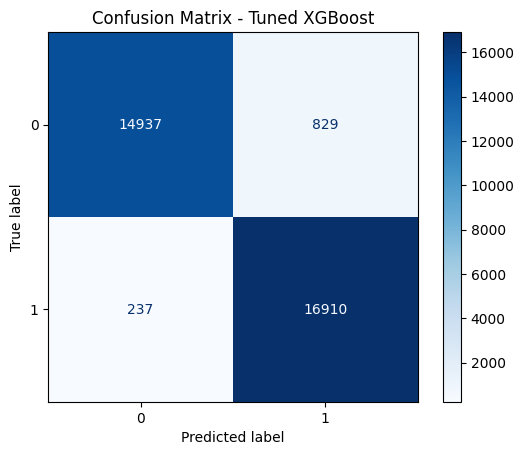

In [110]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned XGBoost")
plt.show()

In [111]:
import pickle

with open("optimized_xgboost_model.pkl", "wb") as f:
    pickle.dump(best_xgb, f)

with open("tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)                         #saving the final model


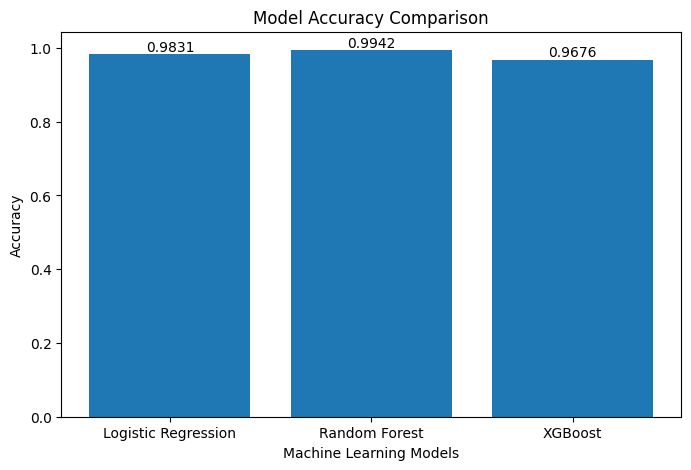

In [112]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(comparison["Model"], comparison["Accuracy"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

for i, value in enumerate(comparison["Accuracy"]):
    plt.text(i, value, f"{value:.4f}", ha="center", va="bottom")

plt.show()

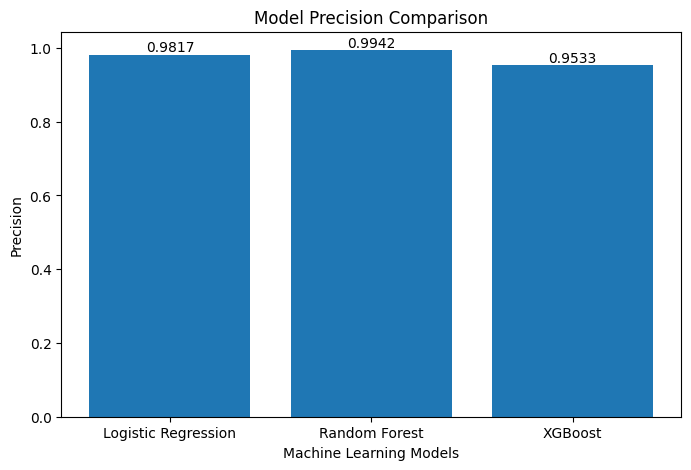

In [113]:
plt.figure(figsize=(8,5))
plt.bar(comparison["Model"], comparison["Precision"])

plt.title("Model Precision Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Precision")

for i, value in enumerate(comparison["Precision"]):
    plt.text(i, value, f"{value:.4f}", ha="center", va="bottom")

plt.show()

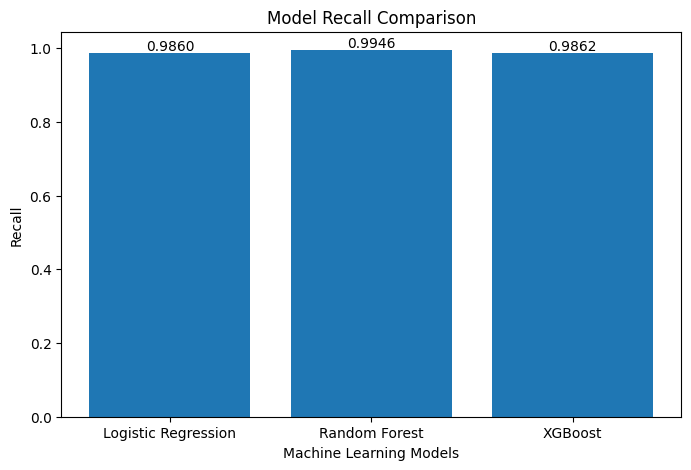

In [114]:
plt.figure(figsize=(8,5))
plt.bar(comparison["Model"], comparison["Recall"])

plt.title("Model Recall Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Recall")

for i, value in enumerate(comparison["Recall"]):
    plt.text(i, value, f"{value:.4f}", ha="center", va="bottom")

plt.show()

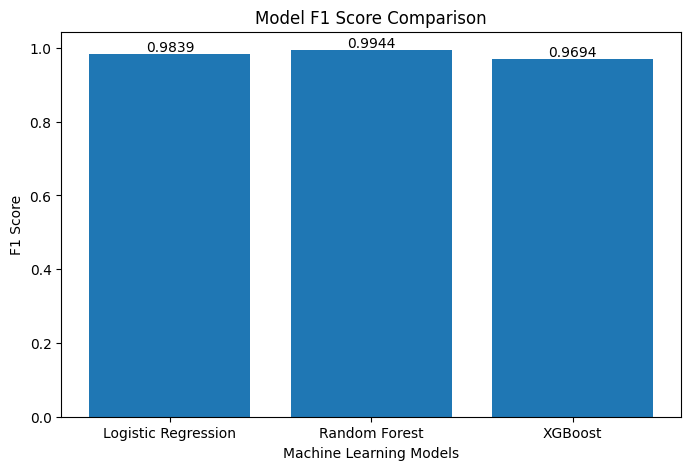

In [115]:
plt.figure(figsize=(8,5))
plt.bar(comparison["Model"], comparison["F1 Score"])

plt.title("Model F1 Score Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")

for i, value in enumerate(comparison["F1 Score"]):
    plt.text(i, value, f"{value:.4f}", ha="center", va="bottom")

plt.show()

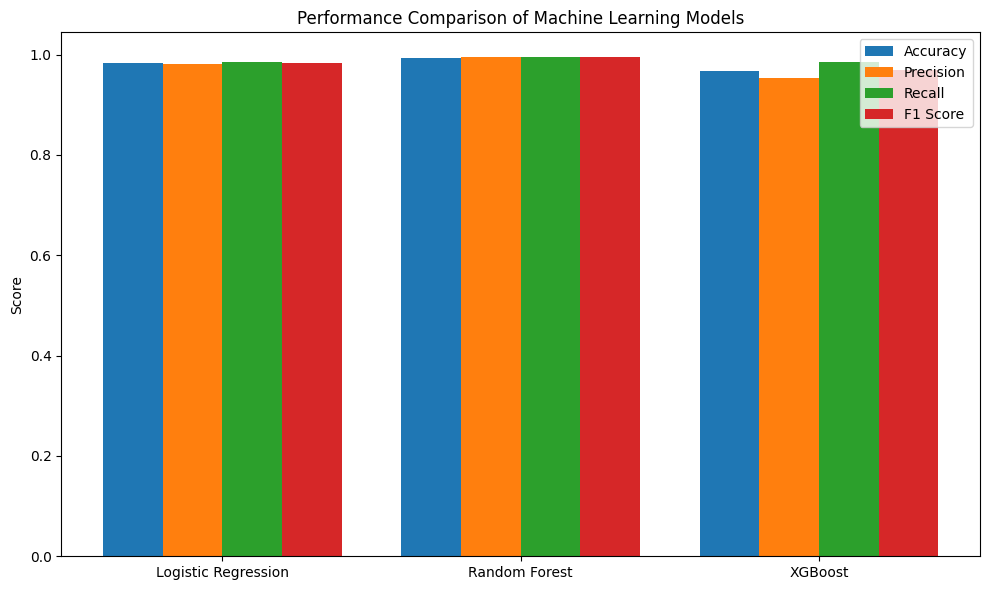

In [116]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
x = np.arange(len(comparison["Model"]))
width = 0.2

plt.figure(figsize=(10,6))

for i, metric in enumerate(metrics):
    plt.bar(x + i*width, comparison[metric], width, label=metric)

plt.xticks(x + width*1.5, comparison["Model"])
plt.ylabel("Score")
plt.title("Performance Comparison of Machine Learning Models")
plt.legend()

plt.tight_layout()
plt.show()

FINAL EXPERIMENTAL RESULTS

Best Hyperparameters:
{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}

Best Cross-Validation F1 Score:
0.9674

MODEL PERFORMANCE METRICS
Accuracy : 0.9676
Precision: 0.9533
Recall   : 0.9862
F1 Score : 0.9694

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.98      0.95      0.97     15766
           1       0.95      0.99      0.97     17147

    accuracy                           0.97     32913
   macro avg       0.97      0.97      0.97     32913
weighted avg       0.97      0.97      0.97     32913


CONFUSION MATRIX
[[14937   829]
 [  237 16910]]


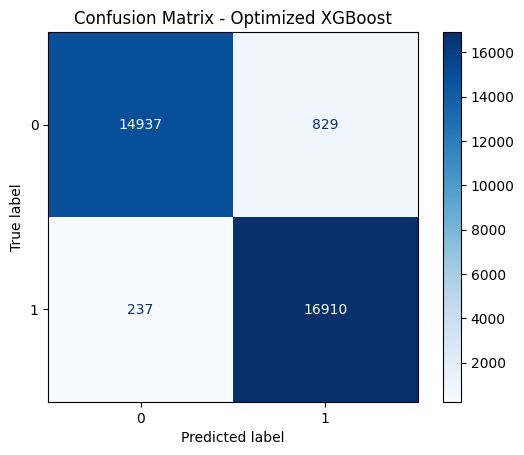


EXPERIMENT COMPLETED SUCCESSFULLY


In [119]:
# ==========================================================
# FINAL EXPERIMENTAL RESULTS - OPTIMIZED XGBOOST MODEL--- FOR MY REF
# ==========================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# -----------------------------
# Display Best Hyperparameters
# -----------------------------
print("="*70)
print("FINAL EXPERIMENTAL RESULTS")
print("="*70)

print("\nBest Hyperparameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(f"{random_search.best_score_:.4f}")

# -----------------------------
# Calculate Evaluation Metrics
# -----------------------------
accuracy = accuracy_score(y_test, best_pred)
precision = precision_score(y_test, best_pred)
recall = recall_score(y_test, best_pred)
f1 = f1_score(y_test, best_pred)

print("\n" + "="*70)
print("MODEL PERFORMANCE METRICS")
print("="*70)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

# -----------------------------
# Classification Report
# -----------------------------
print("\n" + "="*70)
print("CLASSIFICATION REPORT")
print("="*70)

print(classification_report(y_test, best_pred))

# -----------------------------
# Confusion Matrix
# -----------------------------
cm = confusion_matrix(y_test, best_pred)

print("\n" + "="*70)
print("CONFUSION MATRIX")
print("="*70)

print(cm)

# -----------------------------
# Display Confusion Matrix
# -----------------------------
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Optimized XGBoost")
plt.grid(False)
plt.show()

print("\n" + "="*70)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("="*70)